In [1]:
import os
os.chdir("/Users/eloelo/Projects/plant-disease-detection")

import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay

print("TensorFlow:", tf.__version__)
print("Working from:", os.getcwd())

TensorFlow: 2.19.1
Working from: /Users/eloelo/Projects/plant-disease-detection


In [2]:
image_size = (224, 224)
batch_size = 32

test_data = tf.data.Dataset.load("data/splits_tfds/test")

def resize_image(image, label):
    image = tf.image.resize(image, image_size)
    return image, label

test_data = test_data.map(resize_image).batch(batch_size)

class_names = [
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___healthy",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_mosaic_virus",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
]

short_names = []
for name in class_names:
    short_names.append(name.replace("Tomato___", ""))

y_true = []
for images, labels in test_data:
    for label in labels.numpy():
        y_true.append(int(label))

y_true = np.array(y_true)

print("Test images:", len(y_true))
print("Test batches:", len(test_data))

2026-09-28 23:45:11.261088: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Pro
2026-09-28 23:45:11.261180: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-09-28 23:45:11.261189: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
I0000 00:00:1790619311.261781  960781 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1790619311.261858  960781 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Test images: 1825
Test batches: 58


2026-09-28 23:45:11.469054: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [3]:
baseline_model = keras.models.load_model("models/baseline_cnn.keras")
mobilenet_frozen = keras.models.load_model("models/mobilenet_frozen.keras")
mobilenet_finetuned = keras.models.load_model("models/mobilenet_finetuned.keras")
resnet_frozen = keras.models.load_model("models/resnet_frozen.keras")

def prepare_for_baseline(image, label):
    return image / 255.0, label

def prepare_for_resnet(image, label):
    return keras.applications.resnet50.preprocess_input(image), label

baseline_test = test_data.map(prepare_for_baseline)
mobilenet_test = test_data
resnet_test = test_data.map(prepare_for_resnet)

print("All 4 models loaded")

All 4 models loaded


In [4]:
models_to_test = [
    ("Baseline CNN", baseline_model, baseline_test),
    ("MobileNetV2 frozen", mobilenet_frozen, mobilenet_test),
    ("MobileNetV2 fine-tuned", mobilenet_finetuned, mobilenet_test),
    ("ResNet50 frozen", resnet_frozen, resnet_test),
]

predictions = {}

for name, model, data in models_to_test:
    probabilities = model.predict(data, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    accuracy = np.mean(y_pred == y_true)
    macro_f1 = f1_score(y_true, y_pred, average="macro")

    predictions[name] = y_pred

    print(name)
    print("  Test accuracy:", round(accuracy * 100, 2), "%")
    print("  Macro-F1:     ", round(macro_f1, 4))

2026-09-28 23:45:14.269839: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


Baseline CNN
  Test accuracy: 90.19 %
  Macro-F1:      0.8665
MobileNetV2 frozen
  Test accuracy: 91.51 %
  Macro-F1:      0.8818
MobileNetV2 fine-tuned
  Test accuracy: 96.82 %
  Macro-F1:      0.9523
ResNet50 frozen
  Test accuracy: 96.66 %
  Macro-F1:      0.958


In [5]:
for name in ["MobileNetV2 fine-tuned", "ResNet50 frozen"]:
    print(name)
    print(classification_report(y_true, predictions[name], target_names=short_names, digits=3))
    print()

MobileNetV2 fine-tuned
                                      precision    recall  f1-score   support

                      Bacterial_spot      0.972     0.991     0.981       214
                        Early_blight      0.975     0.780     0.867       100
                             healthy      0.958     1.000     0.979       160
                         Late_blight      0.979     0.974     0.977       192
                           Leaf_Mold      0.979     0.979     0.979        96
                  Septoria_leaf_spot      0.961     0.972     0.966       178
Spider_mites Two-spotted_spider_mite      0.958     0.953     0.955       169
                         Target_Spot      0.855     0.965     0.907       141
                 Tomato_mosaic_virus      1.000     0.842     0.914        38
       Tomato_Yellow_Leaf_Curl_Virus      1.000     0.994     0.997       537

                            accuracy                          0.968      1825
                           macro avg   

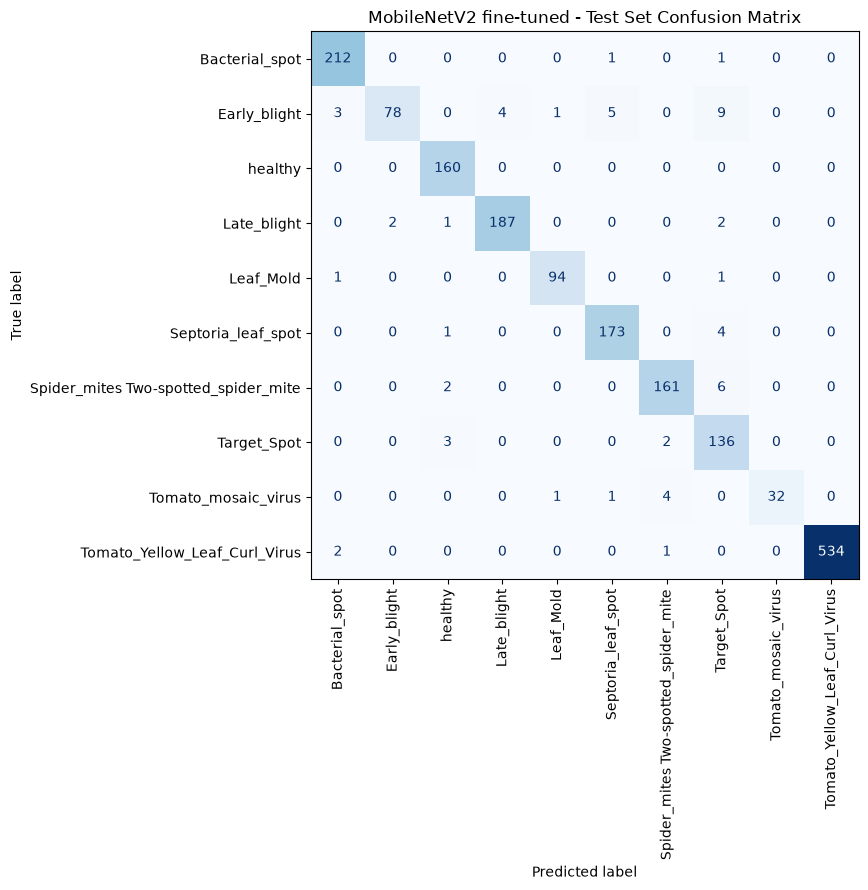

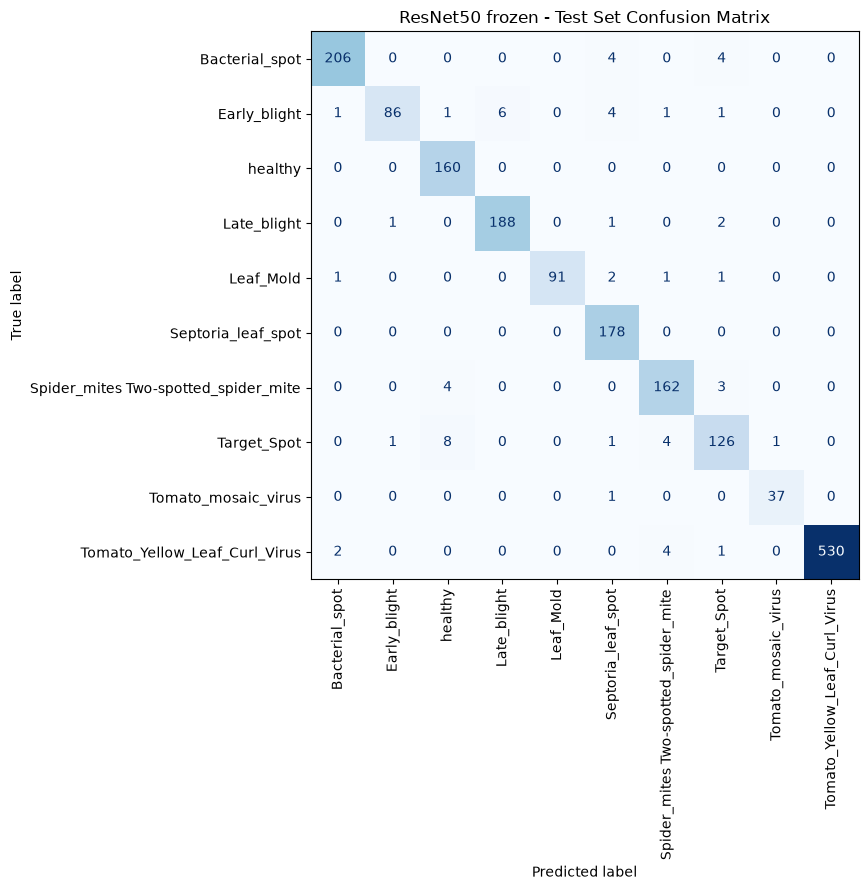

In [6]:
for name in ["MobileNetV2 fine-tuned", "ResNet50 frozen"]:
    cm = confusion_matrix(y_true, predictions[name])

    fig, ax = plt.subplots(figsize=(10, 9))
    display = ConfusionMatrixDisplay(cm, display_labels=short_names)
    display.plot(ax=ax, xticks_rotation=90, colorbar=False, cmap="Blues")
    plt.title(name + " - Test Set Confusion Matrix")
    plt.tight_layout()

    file_name = name.lower().replace(" ", "_").replace("-", "_")
    plt.savefig("reports/figures/confusion_" + file_name + ".png", dpi=150)
    plt.show()

Wrong predictions: 58


2026-09-28 23:45:34.241610: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


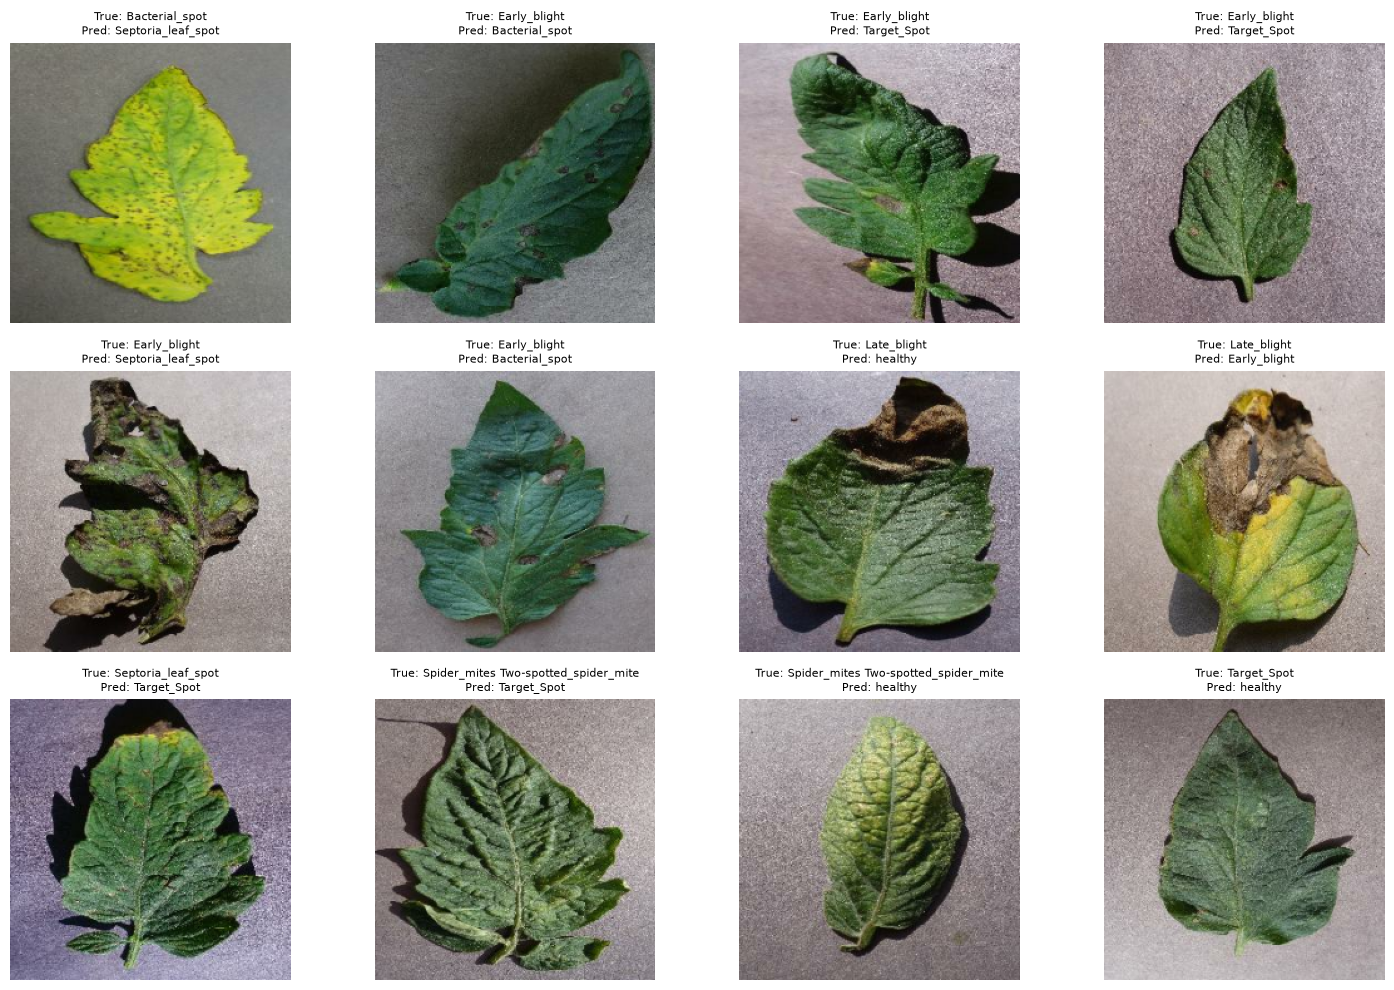

In [7]:
y_pred = predictions["MobileNetV2 fine-tuned"]
wrong = np.where(y_pred != y_true)[0]
print("Wrong predictions:", len(wrong))

wrong_images = []
index = 0
for images, labels in test_data:
    for image in images.numpy():
        if index in wrong:
            wrong_images.append((index, image))
        index += 1

plt.figure(figsize=(15, 10))
for i in range(12):
    step = len(wrong_images) // 12
    idx, image = wrong_images[i * step]    
    plt.subplot(3, 4, i + 1)
    plt.imshow(image.astype("uint8"))
    plt.title("True: " + short_names[y_true[idx]] + "\nPred: " + short_names[y_pred[idx]], fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.savefig("reports/figures/mobilenet_wrong_predictions.png", dpi=150)
plt.show()

### Test set results
- Test set used only here, never for training or choosing models
- Test results within about 1 point of val for every model, so the models generalise
- MobileNetV2 fine-tuned 96.8% acc (macro-F1 0.952), ResNet50 frozen 96.7% (0.958): basically tied
- Baseline 90.2% (0.867): biggest gap between accuracy and macro-F1, so weakest on small classes
- MobileNetV2 hardest class: Early_blight (78 of 100), mostly mistaken for Target_Spot
- Mosaic virus: 32 of 38, the 6 missed went to other diseases, never to healthy
- Diseased leaves called healthy: MobileNetV2 7, ResNet50 13
- Most errors are look-alike diseases or leaves with faint symptoms, but one Late_blight leaf with a large dead patch at the edge was called healthy, so the model can miss damage that covers only part of the leaf
- Chosen for the app: MobileNetV2 fine-tuned, as accurate, 10x smaller, and fewer sick called healthy mistakes

In [8]:
import time

for name, model, data in models_to_test:
    probabilities = model.predict(data, verbose=0)
    top3_indices = np.argsort(probabilities, axis=1)[:, -3:]

    correct = 0
    for i in range(len(y_true)):
        if y_true[i] in top3_indices[i]:
            correct += 1
    top3_accuracy = correct / len(y_true)

    for images, labels in data.take(1):
        one_image = images[:1]

    model.predict(one_image, verbose=0)

    start = time.perf_counter()
    for i in range(50):
        model.predict(one_image, verbose=0)
    latency_ms = (time.perf_counter() - start) / 50 * 1000

    print(name)
    print("  Top-3 accuracy:", round(top3_accuracy * 100, 2), "%")
    print("  Latency per image:", round(latency_ms, 1), "ms")
    

Baseline CNN
  Top-3 accuracy: 98.52 %
  Latency per image: 23.8 ms


2026-09-28 23:45:39.480019: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


MobileNetV2 frozen
  Top-3 accuracy: 99.01 %
  Latency per image: 36.9 ms
MobileNetV2 fine-tuned
  Top-3 accuracy: 99.73 %
  Latency per image: 36.6 ms
ResNet50 frozen
  Top-3 accuracy: 99.73 %
  Latency per image: 36.2 ms


### Summary of test results

| Model | Accuracy | Macro-F1 | Top-3 accuracy | Latency per image |
|---|---|---|---|---|
| Baseline CNN | 90.2% | 0.867 | 98.5% | 23.8 ms |
| MobileNetV2 frozen | 91.5% | 0.882 | 99.0% | 36.9 ms |
| MobileNetV2 fine-tuned | 96.8% | 0.952 | 99.7% | 36.6 ms |
| ResNet50 frozen | 96.7% | 0.958 | 99.7% | 36.2 ms |

- Top-3 accuracy 99.7% for the two best models: the right class is almost always in the top 3, so the app shows the top 3
- MobileNetV2 and ResNet50 take about the same time, so I picked MobileNetV2 for its size (2.3M vs 23.6M parameters), not speed

### Is the model usable for the target users?
- Yes, as a first screening tool for farm advisors and field workers: 96.8% accuracy, 99.7% top-3, instant answers
- Only for tomato leaves photographed like the dataset: one leaf, plain background
- Not tested on field photos with soil, other leaves or poor light, so accuracy there is unknown
- Weakest on Early_blight (78% found), often mistaken for Target_Spot
- 7 of the 1,665 diseased test leaves were called healthy, so a "healthy" result should not stop an expert check
- Advisory and educational use only, not a final diagnosis; the app will show confidence scores and these limitations